# EDA 2 · Reciclaje y tratamiento de residuos en la UE

**Objetivo.** Comparar la recuperación mediante reciclaje entre países, contrastar la hipótesis nórdica y la relación con PIB per cápita, y estudiar qué tipos de residuos se reciclan o se eliminan.

**Fuente principal:** Eurostat, `env_wastrt_linear.csv.gz` (el mismo fichero utilizado en `Limpieza_tratamiento.ipynb`).


## 0. Preparación y carga

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr, mannwhitneyu

UE = "Unión Europea (UE-27)"

# Estilo común para todos los gráficos del proyecto
import matplotlib as mpl

PALETA_RESIDUOS = {
    "azul": "#264653",
    "verde": "#2A9D8F",
    "amarillo": "#E9C46A",
    "naranja": "#F4A261",
    "coral": "#E76F51",
    "gris": "#6C757D",
}

sns.set_theme(
    style="whitegrid",
    context="notebook",
    font="DejaVu Sans",
    palette=[
        PALETA_RESIDUOS["azul"],
        PALETA_RESIDUOS["verde"],
        PALETA_RESIDUOS["amarillo"],
        PALETA_RESIDUOS["naranja"],
        PALETA_RESIDUOS["coral"],
        PALETA_RESIDUOS["gris"],
    ],
)

mpl.rcParams.update({
    "figure.figsize": (10, 5.8),
    "figure.dpi": 110,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "#D9E1E5",
    "axes.labelcolor": "#35434A",
    "axes.titlecolor": "#20343B",
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 10.5,
    "axes.titlepad": 14,
    "font.size": 10,
    "xtick.color": "#52636B",
    "ytick.color": "#52636B",
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "grid.color": "#DCE4E8",
    "grid.linestyle": "--",
    "grid.linewidth": 0.7,
    "grid.alpha": 0.75,
    "legend.frameon": False,
    "legend.fontsize": 9,
    "lines.linewidth": 2.4,
    "lines.markersize": 6,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

# Mantener una apariencia equivalente en los gráficos interactivos de Plotly
PLOTLY_TEMPLATE = "plotly_white"


In [2]:
# Importamos los datos
df = pd.read_csv('./Data/trt_residuos.csv')

In [3]:
df.head()

,pais,year,peligrosidad,tratamiento,residuo,kg_per_capita,toneladas,obs_flag,conf_status
0,Austria,2010,Peligrosos,Eliminación - incineración (D10),"Residuos ácidos, alcalinos o salinos",0.0,44.0,NaN,NaN
1,Austria,2012,Peligrosos,Eliminación - incineración (D10),"Residuos ácidos, alcalinos o salinos",NaN,NaN,NaN,C
2,Austria,2014,Peligrosos,Eliminación - incineración (D10),"Residuos ácidos, alcalinos o salinos",NaN,NaN,NaN,C
3,Austria,2016,Peligrosos,Eliminación - incineración (D10),"Residuos ácidos, alcalinos o salinos",NaN,NaN,NaN,C
4,Austria,2018,Peligrosos,Eliminación - incineración (D10),"Residuos ácidos, alcalinos o salinos",NaN,NaN,NaN,C


## 1. Comprobaciones iniciales

In [4]:
print("Dimensiones:", df.shape)
display("Operaciones:", sorted(df["tratamiento"].dropna().unique()))
print("Nº países:", df["pais"].nunique())
display(df.isna().mean().sort_values(ascending=False).to_frame("proporción_NA").head(12))

Dimensiones: (227136, 9)


'Operaciones:'

['Eliminación - depósito en vertedero (D1, D5, D12)',
 'Eliminación - depósito en vertedero y otros (D1-D7, D12)',
 'Eliminación - incineración (D10)',
 'Eliminación - otros (D2-D4, D6-D7)',
 'Tratamiento de residuos',
 'Valorización - reciclado',
 'Valorización - reciclado y relleno (R2-R11)',
 'Valorización - relleno',
 'Valorización - valorización energética (R1)']

Nº países: 28


,proporción_NA
conf_status,0.980853
obs_flag,0.848558
kg_per_capita,0.151689
toneladas,0.151689
pais,0.000000
residuo,0.000000
tratamiento,0.000000
peligrosidad,0.000000
year,0.000000


## Evolución de la tasa de reciclaje en la UE
Tomamos el total de residuos y el agregado de peligrosos y no peligrosos. La tasa se calcula como toneladas en `Valorización - reciclado` divididas por toneladas en `Tratamiento de residuos`. Esto mantiene el denominador explícito y evita sumar categorías de residuos solapadas.

tratamiento,Tratamiento de residuos,Valorización - reciclado,Reciclaje_prop
year,,,
2004,1.897000e+09,NaN,NaN
2006,1.932880e+09,NaN,NaN
2008,1.949520e+09,NaN,NaN
2010,2.030040e+09,749460000.0,36.918484
2012,2.111800e+09,749260000.0,35.479686
2014,2.111450e+09,749610000.0,35.502143
2016,2.097150e+09,768900000.0,36.664044
2018,2.172530e+09,826200000.0,38.029394
2020,1.936160e+09,755400000.0,39.015371


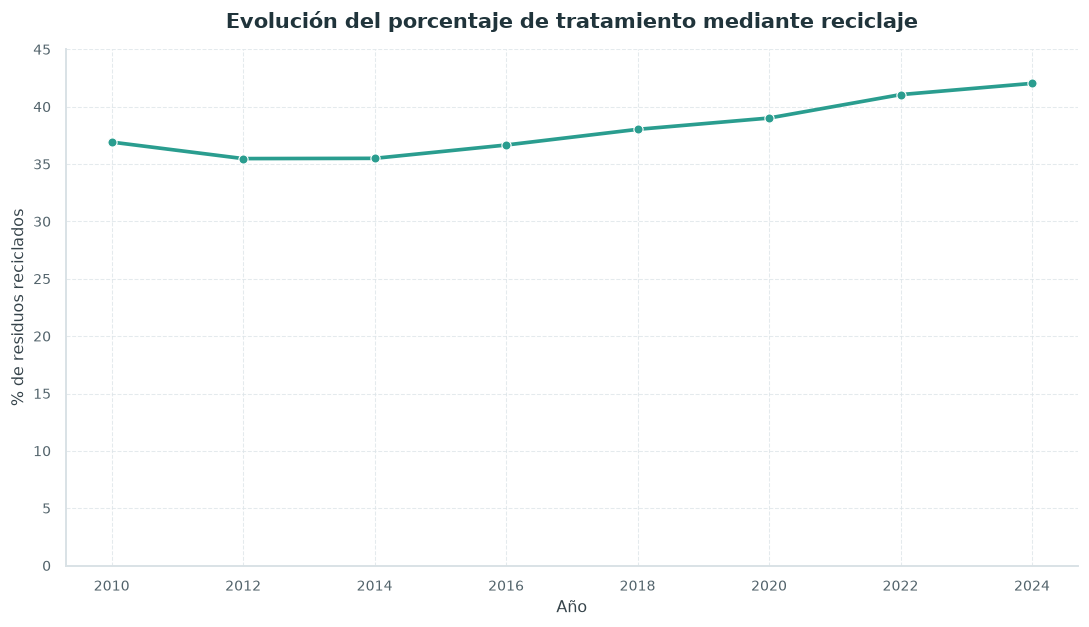

In [5]:
evolucion_ue = df[
    (df["pais"] == UE) &
    (df["residuo"] == "Total de residuos") &
    (df["peligrosidad"] == "Total (peligrosos y no peligrosos)") &
    (df["tratamiento"].isin(["Tratamiento de residuos","Valorización - reciclado"]))
].pivot_table(index="year", columns="tratamiento", values="toneladas", aggfunc="sum")

evolucion_ue["Reciclaje_prop"] = 100 * evolucion_ue["Valorización - reciclado"] / evolucion_ue["Tratamiento de residuos"]

display(evolucion_ue)


sns.lineplot(
    x=evolucion_ue.index, 
    y=evolucion_ue["Reciclaje_prop"], 
    color=PALETA_RESIDUOS["verde"],
    marker="o"
)

plt.title("Evolución del porcentaje de tratamiento mediante reciclaje")
plt.xlabel("Año")
plt.ylabel("% de residuos reciclados")
plt.ylim(0, 45)
plt.tight_layout()
plt.show()

## 2. Tasa de reciclaje por país
Para la comparación internacional tomamos el año 2024, el total de residuos y el agregado de peligrosos y no peligrosos. La tasa se calcula como toneladas en `Valorización - reciclado` divididas por toneladas en `Tratamiento de residuos`. Esto mantiene el denominador explícito y evita sumar categorías de residuos solapadas.

tratamiento,Tratamiento de residuos,Valorización - reciclado,Reciclaje_prop
pais,,,
Italia,1.676797e+08,146459518.0,87.344827
Hungría,2.171083e+07,16746957.0,77.136434
Eslovaquia,8.828051e+06,6158593.0,69.761638
Bélgica,5.432873e+07,37501738.0,69.027448
Croacia,5.366970e+06,3401724.0,63.382579
Letonia,1.767557e+06,1105767.0,62.559058
Países Bajos,1.023820e+08,57901500.0,56.554375
Chequia,3.216146e+07,18088657.0,56.243271
Lituania,4.049749e+06,2198228.0,54.280599


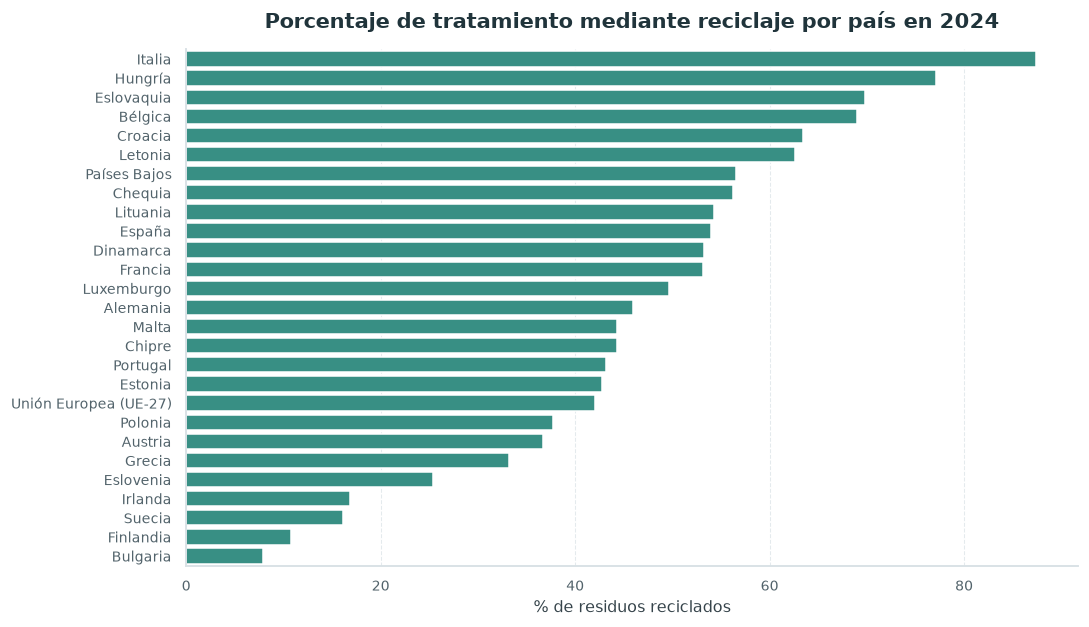

In [6]:
reci_pais = df[
    (df["year"] == 2024) &
    (df["residuo"] == "Total de residuos") &
    (df["peligrosidad"] == "Total (peligrosos y no peligrosos)") &
    (df["tratamiento"].isin(["Tratamiento de residuos","Valorización - reciclado"]))
].pivot_table(index="pais", columns="tratamiento", values="toneladas", aggfunc="sum")

reci_pais["Reciclaje_prop"] = 100 * reci_pais["Valorización - reciclado"] / reci_pais["Tratamiento de residuos"]

reci_pais = reci_pais.sort_values("Reciclaje_prop", ascending=False)
display(reci_pais)


sns.barplot(
    x=reci_pais["Reciclaje_prop"], 
    y=reci_pais.index, 
    color=PALETA_RESIDUOS["verde"])
plt.title(f"Porcentaje de tratamiento mediante reciclaje por país en 2024")
plt.xlabel("% de residuos reciclados")
plt.ylabel("")
plt.tight_layout()
plt.show()

### Para ver no solo el porcentaje que se recicla, si no que la distribución y el **peso de cada tipo de tratamiento por país**:

In [7]:
trt_2024 = df[
    (df["year"] == 2024) &
    (df["residuo"] == "Total de residuos") &
    (df["peligrosidad"] == "Total (peligrosos y no peligrosos)")
]

trt_2024.head()

,pais,year,peligrosidad,tratamiento,residuo,kg_per_capita,toneladas,obs_flag,conf_status
81242,Austria,2024,Total (peligrosos y no peligrosos),Eliminación - incineración (D10),Total de residuos,NaN,NaN,NaN,C
81253,Bélgica,2024,Total (peligrosos y no peligrosos),Eliminación - incineración (D10),Total de residuos,21.0,248342.0,NaN,NaN
81264,Bulgaria,2024,Total (peligrosos y no peligrosos),Eliminación - incineración (D10),Total de residuos,0.0,2829.0,NaN,NaN
81275,Croacia,2024,Total (peligrosos y no peligrosos),Eliminación - incineración (D10),Total de residuos,0.0,0.0,NaN,NaN
81286,Chipre,2024,Total (peligrosos y no peligrosos),Eliminación - incineración (D10),Total de residuos,0.0,7.0,NaN,NaN


In [8]:
# Comprobamos si hay algún "flag"
trt_2024[['obs_flag', 'conf_status']].notna().sum().to_frame(name='valores_no_nan')

,valores_no_nan
obs_flag,27
conf_status,2


In [9]:
trt_2024[~trt_2024["obs_flag"].isna()]

,pais,year,peligrosidad,tratamiento,residuo,kg_per_capita,toneladas,obs_flag,conf_status
81308,Dinamarca,2024,Total (peligrosos y no peligrosos),Eliminación - incineración (D10),Total de residuos,0.0,9.600000e+01,b,NaN
81330,Unión Europea (UE-27),2024,Total (peligrosos y no peligrosos),Eliminación - incineración (D10),Total de residuos,17.0,7.600000e+06,i,NaN
81374,Grecia,2024,Total (peligrosos y no peligrosos),Eliminación - incineración (D10),Total de residuos,1.0,8.510000e+03,p,NaN
90037,Dinamarca,2024,Total (peligrosos y no peligrosos),"Eliminación - depósito en vertedero (D1, D5, D12)",Total de residuos,298.0,1.782919e+06,b,NaN
90059,Unión Europea (UE-27),2024,Total (peligrosos y no peligrosos),"Eliminación - depósito en vertedero (D1, D5, D12)",Total de residuos,1299.0,5.847200e+08,i,NaN
90103,Grecia,2024,Total (peligrosos y no peligrosos),"Eliminación - depósito en vertedero (D1, D5, D12)",Total de residuos,1037.0,1.076036e+07,p,NaN
98682,Dinamarca,2024,Total (peligrosos y no peligrosos),Eliminación - depósito en vertedero y otros (D...,Total de residuos,298.0,1.782919e+06,b,NaN
98704,Unión Europea (UE-27),2024,Total (peligrosos y no peligrosos),Eliminación - depósito en vertedero y otros (D...,Total de residuos,1643.0,7.394300e+08,i,NaN
98748,Grecia,2024,Total (peligrosos y no peligrosos),Eliminación - depósito en vertedero y otros (D...,Total de residuos,1099.0,1.140084e+07,p,NaN
107314,Dinamarca,2024,Total (peligrosos y no peligrosos),"Eliminación - otros (D2-D4, D6-D7)",Total de residuos,0.0,0.000000e+00,b,NaN


In [10]:
trt_2024[trt_2024["toneladas"].isna()]

,pais,year,peligrosidad,tratamiento,residuo,kg_per_capita,toneladas,obs_flag,conf_status
81242,Austria,2024,Total (peligrosos y no peligrosos),Eliminación - incineración (D10),Total de residuos,NaN,NaN,NaN,C
123528,Austria,2024,Total (peligrosos y no peligrosos),Valorización - valorización energética (R1),Total de residuos,NaN,NaN,NaN,C


In [11]:
# Vemos que Austria tiene un par de valores como NaN

trt_2024[trt_2024["pais"] == "Austria"]

,pais,year,peligrosidad,tratamiento,residuo,kg_per_capita,toneladas,obs_flag,conf_status
81242,Austria,2024,Total (peligrosos y no peligrosos),Eliminación - incineración (D10),Total de residuos,NaN,NaN,NaN,C
89971,Austria,2024,Total (peligrosos y no peligrosos),"Eliminación - depósito en vertedero (D1, D5, D12)",Total de residuos,2750.0,25240064.0,NaN,NaN
98616,Austria,2024,Total (peligrosos y no peligrosos),Eliminación - depósito en vertedero y otros (D...,Total de residuos,2750.0,25240064.0,NaN,NaN
107250,Austria,2024,Total (peligrosos y no peligrosos),"Eliminación - otros (D2-D4, D6-D7)",Total de residuos,0.0,0.0,NaN,NaN
115216,Austria,2024,Total (peligrosos y no peligrosos),Valorización - relleno,Total de residuos,1202.0,11030840.0,NaN,NaN
123528,Austria,2024,Total (peligrosos y no peligrosos),Valorización - valorización energética (R1),Total de residuos,NaN,NaN,NaN,C
131582,Austria,2024,Total (peligrosos y no peligrosos),Valorización - reciclado,Total de residuos,2517.0,23105431.0,NaN,NaN
140314,Austria,2024,Total (peligrosos y no peligrosos),Valorización - reciclado y relleno (R2-R11),Total de residuos,3719.0,34136272.0,NaN,NaN
149715,Austria,2024,Total (peligrosos y no peligrosos),Tratamiento de residuos,Total de residuos,6860.0,62957957.0,NaN,NaN


In [12]:
# Enredando en Eurostat, estimamos los datos de un gráfico

trt_2024.loc[
    (trt_2024["pais"] == "Austria") & (trt_2024["tratamiento"] == "Eliminación - incineración (D10)"),
    "toneladas"
] = 147551

trt_2024.loc[
    (trt_2024["pais"] == "Austria") & (trt_2024["tratamiento"] == "Valorización - valorización energética (R1)"),
    "toneladas"
] = 3434070

In [13]:
# Quitamos algunas de los tipos de tratamientos, ya que algunos engloban a otros.

treatments = [
    'Eliminación - incineración (D10)',
    'Eliminación - depósito en vertedero (D1, D5, D12)',
    'Eliminación - otros (D2-D4, D6-D7)',
    'Valorización - relleno',
    'Valorización - valorización energética (R1)',
    'Valorización - reciclado',
    'Tratamiento de residuos'
]

trt_2024 = trt_2024[trt_2024['tratamiento'].isin(treatments)]

In [14]:
tabla = trt_2024.pivot_table(
    index="pais",
    columns="tratamiento",
    values="toneladas",
    aggfunc="sum",
    fill_value=0
)

tabla

tratamiento,"Eliminación - depósito en vertedero (D1, D5, D12)",Eliminación - incineración (D10),"Eliminación - otros (D2-D4, D6-D7)",Tratamiento de residuos,Valorización - reciclado,Valorización - relleno,Valorización - valorización energética (R1)
pais,,,,,,,
Alemania,59113814.0,1789496.0,66995.0,3.332377e+08,153252006.0,75194434.0,43820980.0
Austria,25240064.0,147551.0,0.0,6.295796e+07,23105431.0,11030840.0,3434070.0
Bulgaria,42492580.0,2829.0,30845199.0,8.025027e+07,6331102.0,0.0,578562.0
Bélgica,3331162.0,248342.0,0.0,5.432873e+07,37501738.0,7922970.0,5324521.0
Chequia,4733531.0,65941.0,2956.0,3.216146e+07,18088657.0,7844701.0,1425675.0
Chipre,551033.0,7.0,0.0,2.703366e+06,1197973.0,788100.0,166253.0
Croacia,1659921.0,0.0,2136.0,5.366970e+06,3401724.0,172517.0,130672.0
Dinamarca,1782919.0,96.0,0.0,1.739461e+07,9253637.0,1666267.0,4691695.0
Eslovaquia,2038089.0,4150.0,14318.0,8.828051e+06,6158593.0,0.0,612902.0


In [15]:
distribucion_trt = tabla.div(tabla["Tratamiento de residuos"], axis=0) * 100

In [16]:
distribucion_trt

tratamiento,"Eliminación - depósito en vertedero (D1, D5, D12)",Eliminación - incineración (D10),"Eliminación - otros (D2-D4, D6-D7)",Tratamiento de residuos,Valorización - reciclado,Valorización - relleno,Valorización - valorización energética (R1)
pais,,,,,,,
Alemania,17.739232,0.537003,0.020104,100.0,45.988792,22.564802,13.150066
Austria,40.090348,0.234364,0.000000,100.0,36.699779,17.520962,5.454545
Bulgaria,52.950076,0.003525,38.436255,100.0,7.889197,0.000000,0.720947
Bélgica,6.131492,0.457110,0.000000,100.0,69.027448,14.583388,9.800562
Chequia,14.718023,0.205031,0.009191,100.0,56.243271,24.391620,4.432868
Chipre,20.383219,0.000259,0.000000,100.0,44.314125,29.152545,6.149852
Croacia,30.928457,0.000000,0.039799,100.0,63.382579,3.214421,2.434744
Dinamarca,10.249834,0.000552,0.000000,100.0,53.198289,9.579212,26.972113
Eslovaquia,23.086511,0.047009,0.162188,100.0,69.761638,0.000000,6.942665


In [17]:
nuevo_orden = [
    "Valorización - reciclado",
    "Valorización - relleno",
    "Valorización - valorización energética (R1)",
    "Eliminación - depósito en vertedero (D1, D5, D12)",
    "Eliminación - otros (D2-D4, D6-D7)",
    "Eliminación - incineración (D10)",
]

# Reordenamos el DataFrame
distribucion_trt = distribucion_trt[nuevo_orden]

distribucion_trt = distribucion_trt.sort_values(
    by="Valorización - reciclado",
    ascending=False
)

In [18]:
distribucion_trt.head()

tratamiento,Valorización - reciclado,Valorización - relleno,Valorización - valorización energética (R1),"Eliminación - depósito en vertedero (D1, D5, D12)","Eliminación - otros (D2-D4, D6-D7)",Eliminación - incineración (D10)
pais,,,,,,
Italia,87.344827,0.243252,4.757620,7.235158,0.000000,0.419143
Hungría,77.136434,0.000000,5.615691,16.900684,0.000000,0.347186
Eslovaquia,69.761638,0.000000,6.942665,23.086511,0.162188,0.047009
Bélgica,69.027448,14.583388,9.800562,6.131492,0.000000,0.457110
Croacia,63.382579,3.214421,2.434744,30.928457,0.039799,0.000000


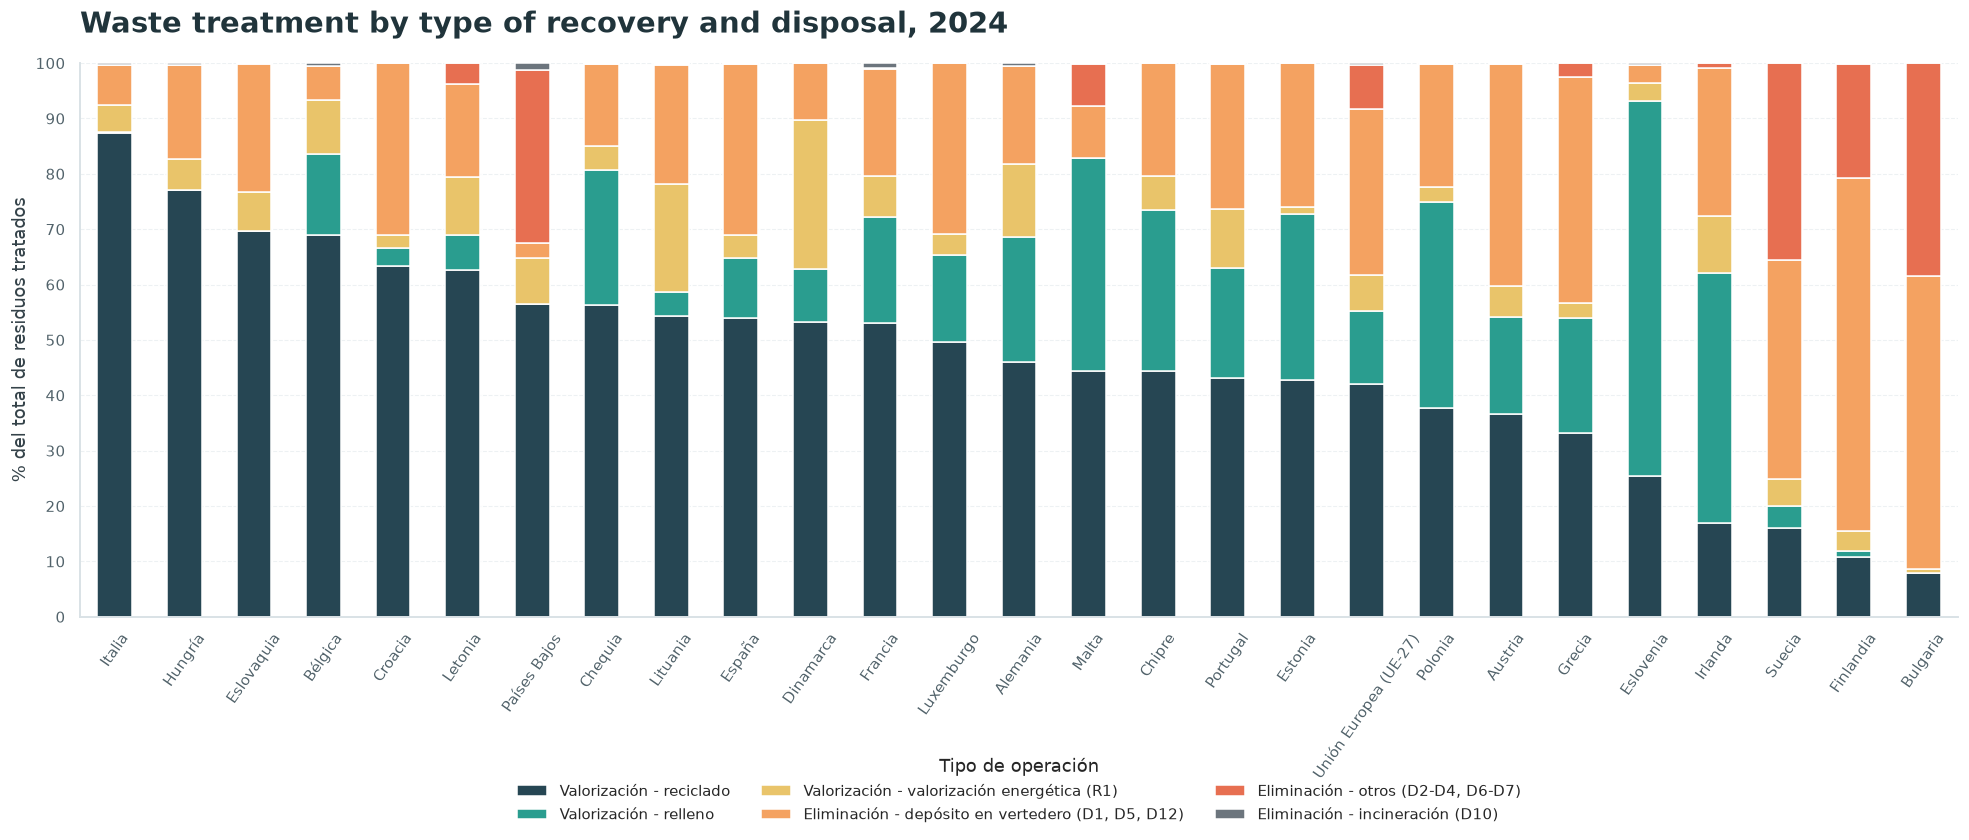

In [19]:
fig, ax = plt.subplots(figsize=(18, 8))

# Gráfico de barras apiladas
distribucion_trt.plot(
    kind="bar",
    stacked=True,
    ax=ax
)

# Eje Y
ax.set_ylim(0, 100)
ax.set_yticks(np.arange(0, 101, 10))
ax.set_ylabel("% del total de residuos tratados", fontsize=12)

# Eje X
ax.set_xlabel("")
ax.tick_params(axis="x", labelrotation=55, labelsize=10)
ax.tick_params(axis="y", labelsize=10)

# Cuadrícula horizontal
ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.5
)

ax.set_axisbelow(True)

# Leyenda
ax.legend(
    title="Tipo de operación",
    loc="upper center",
    bbox_to_anchor=(0.5, -0.23),
    ncol=3,
    frameon=False,
    fontsize=10
)

# Título
ax.set_title(
    "Waste treatment by type of recovery and disposal, 2024",
    fontsize=19,
    fontweight="bold",
    loc="left",
    pad=20
)

# Eliminar bordes superiores y derechos
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

## 3. ¿Los países nórdicos reciclan más?
Comparamos si Dinamarca, Finlandia y Suecia reciclan más que el resto de países de la UE. Se compara su media con la del resto de países de la UE mediante Mann–Whitney unilateral. La prueba evalúa diferencias de distribución/rangos, no causalidad; con solo tres países nórdicos, la potencia estadística es limitada.

In [20]:
nordicos = ["Dinamarca", "Finlandia", "Suecia"]

reciclaje_nordicos = distribucion_trt[["Valorización - reciclado"]].copy()

reciclaje_nordicos["region"] = np.where(
    reciclaje_nordicos.index.isin(nordicos), 
    "Nórdicos", 
    "Resto de UE"
)

reciclaje_nordicos = reciclaje_nordicos[reciclaje_nordicos.index != UE]
reciclaje_nordicos

tratamiento,Valorización - reciclado,region
pais,,
Italia,87.344827,Resto de UE
Hungría,77.136434,Resto de UE
Eslovaquia,69.761638,Resto de UE
Bélgica,69.027448,Resto de UE
Croacia,63.382579,Resto de UE
Letonia,62.559058,Resto de UE
Países Bajos,56.554375,Resto de UE
Chequia,56.243271,Resto de UE
Lituania,54.280599,Resto de UE


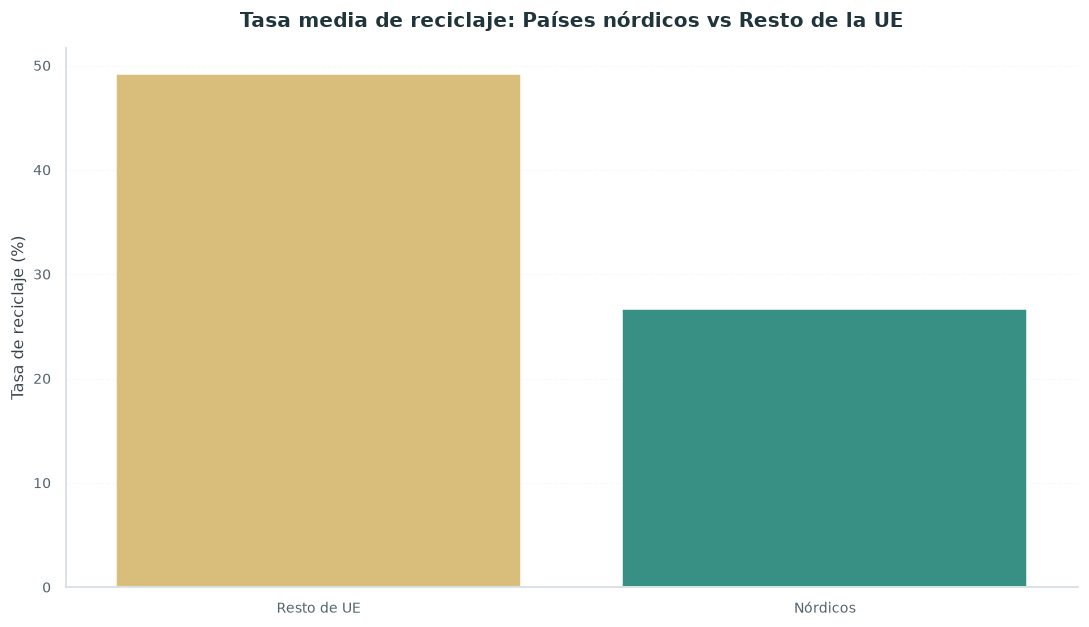

In [21]:
sns.barplot(
    data=reciclaje_nordicos,
    x="region",
    y= "Valorización - reciclado",
    hue="region",
    palette={
        "Nórdicos": PALETA_RESIDUOS["verde"],
        "Resto de UE": PALETA_RESIDUOS["amarillo"]
    },
    errorbar=None,
    estimator="mean",
    legend=False
)

plt.title(
    "Tasa media de reciclaje: Países nórdicos vs Resto de la UE",
    fontsize=13,
    fontweight="bold"
)

plt.xlabel("")
plt.ylabel("Tasa de reciclaje (%)")

plt.grid(axis="y", alpha=0.2)
sns.despine()
plt.tight_layout()
plt.show()

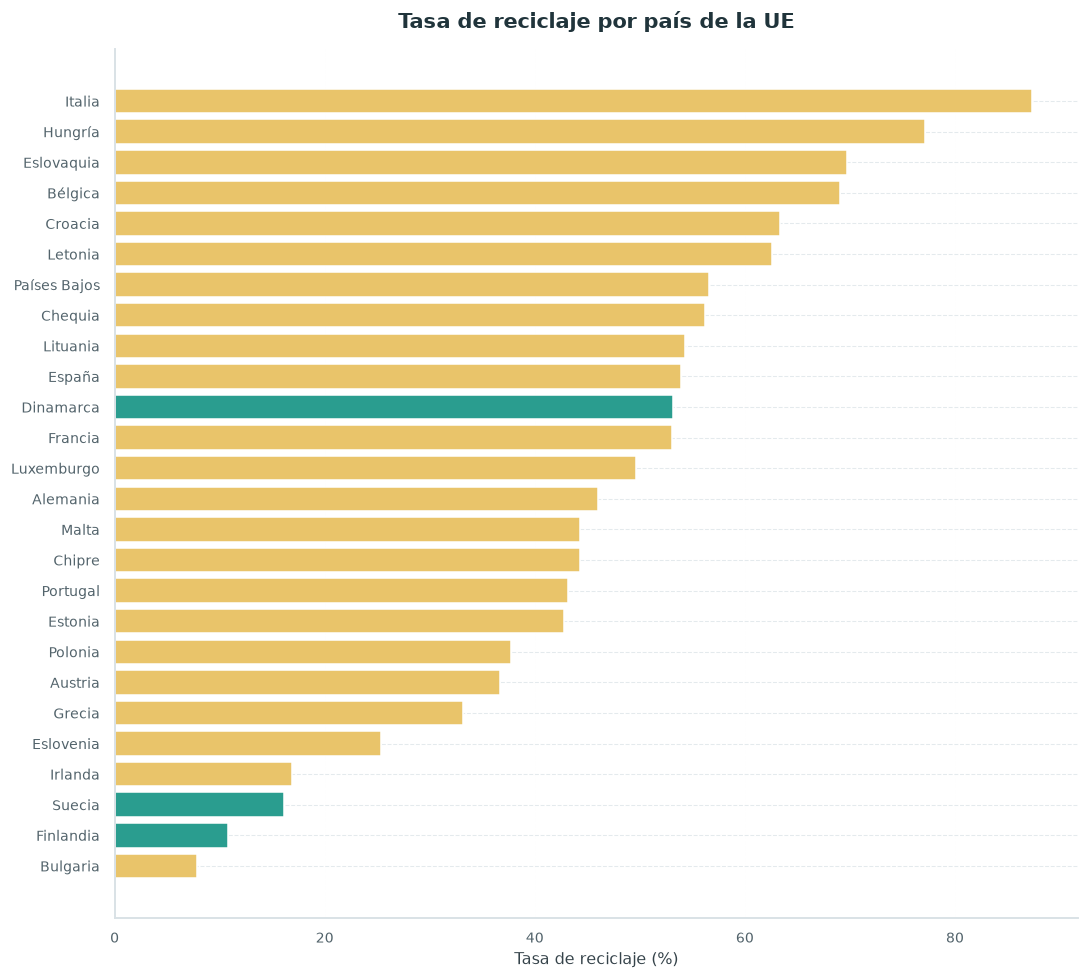

In [22]:
df_ranking = reciclaje_nordicos.sort_values(
    "Valorización - reciclado",
    ascending=True
)

colores = [
    PALETA_RESIDUOS["verde"] if pais in nordicos else PALETA_RESIDUOS["amarillo"]
    for pais in df_ranking.index
]

plt.figure(figsize=(10, 9))

plt.barh(
    df_ranking.index,
    df_ranking["Valorización - reciclado"],
    color=colores
)

plt.title(
    "Tasa de reciclaje por país de la UE",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Tasa de reciclaje (%)")

plt.grid(axis="x", alpha=0.01)
sns.despine()
plt.tight_layout()
plt.show()

In [23]:
grupo_nordico = reciclaje_nordicos.loc[
    reciclaje_nordicos["region"] == "Nórdicos",
    "Valorización - reciclado"
]

grupo_resto = reciclaje_nordicos.loc[
    reciclaje_nordicos["region"] == "Resto de UE",
    "Valorización - reciclado"
]

resultado = mannwhitneyu(
    grupo_nordico,
    grupo_resto,
    alternative="greater"
)

print("Estadístico U:", resultado.statistic)
print("P-valor:", resultado.pvalue)

if resultado.pvalue < 0.05:
    print("Existe evidencia estadística de que los países nórdicos reciclan más.")
else:
    print("No existe evidencia estadística suficiente para afirmar que los países nórdicos reciclan más.")

Estadístico U: 15.0
P-valor: 0.9434615384615386
No existe evidencia estadística suficiente para afirmar que los países nórdicos reciclan más.


,count,mean,median,std
region,,,,
Nórdicos,3,26.681061,16.094711,23.119548
Resto de UE,23,49.186882,49.642381,18.583475


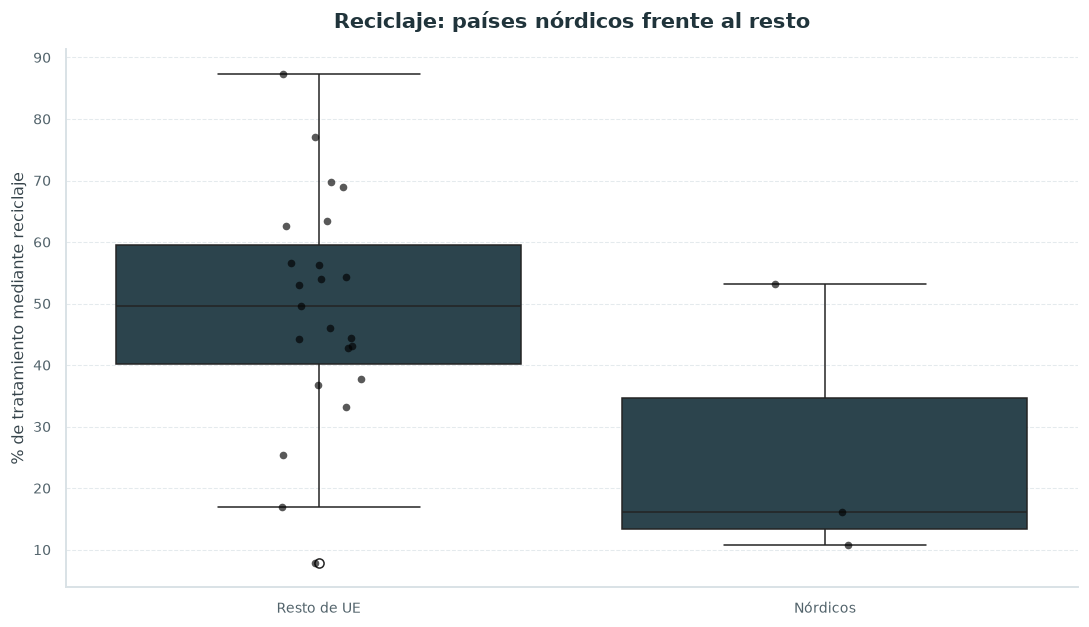

Mann–Whitney U: 15.0 p-valor: 0.9434615384615386


In [24]:
display(
    reciclaje_nordicos.groupby("region")["Valorización - reciclado"].agg(["count", "mean", "median", "std"])
)

# Gráfica
sns.boxplot(data=reciclaje_nordicos, x="region", y="Valorización - reciclado")
sns.stripplot(data=reciclaje_nordicos, x="region", y="Valorización - reciclado", color="black", alpha=0.65)
plt.title("Reciclaje: países nórdicos frente al resto")
plt.xlabel("")
plt.ylabel("% de tratamiento mediante reciclaje")
plt.tight_layout()
plt.show()

# Test Estadístico
g1 = reciclaje_nordicos.loc[reciclaje_nordicos["region"] == "Nórdicos", "Valorización - reciclado"].dropna()
g2 = reciclaje_nordicos.loc[reciclaje_nordicos["region"] == "Resto de UE", "Valorización - reciclado"].dropna()

if len(g1) and len(g2):
    test = mannwhitneyu(g1, g2, alternative="greater")
    print("Mann–Whitney U:", test.statistic, "p-valor:", test.pvalue)
else:
    print("No hay datos suficientes para comparar ambos grupos.")

## 4. ¿Los países con mayor PIB per cápita reciclan más?
Se enlaza la tasa de reciclaje del último año con `gdp_pc_2024.csv`. Se muestran Pearson y Spearman, porque la relación puede no ser lineal y el tamaño muestral es pequeño.

In [25]:
gdp_pc_2024 = pd.read_csv("./Data/gdp_pc_2024.csv")

In [26]:
reci_prop = distribucion_trt[["Valorización - reciclado"]].copy()

In [27]:
reciclaje_gdp = reci_prop.merge(
    gdp_pc_2024,
    on="pais",
    how="left"
)

reciclaje_gdp

,pais,Valorización - reciclado,gdp_pc
0,Italia,87.344827,33050
1,Hungría,77.136434,16220
2,Eslovaquia,69.761638,19320
3,Bélgica,69.027448,44330
4,Croacia,63.382579,17220
5,Letonia,62.559058,16920
6,Países Bajos,56.554375,50870
7,Chequia,56.243271,21950
8,Lituania,54.280599,20090
9,España,53.952222,27820


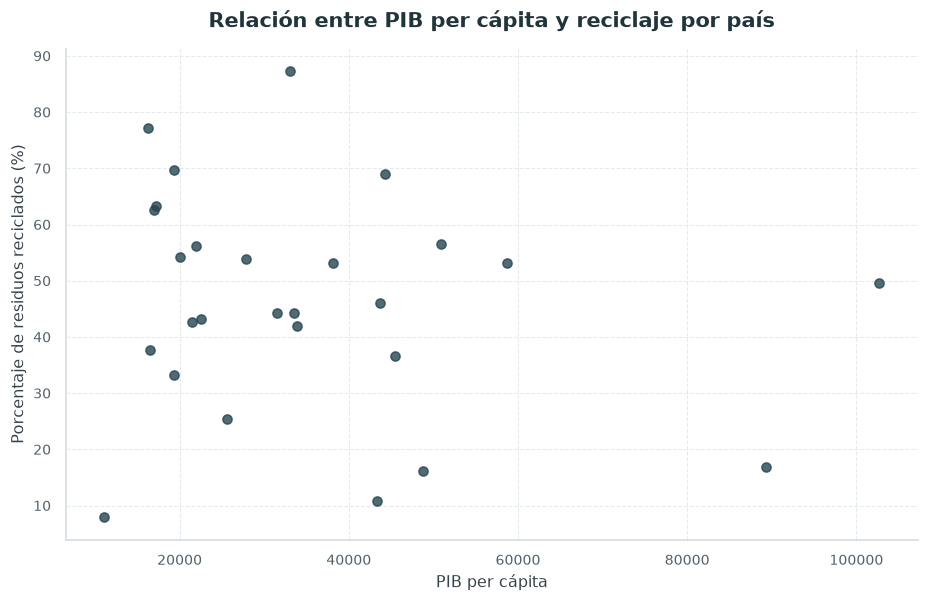

In [28]:
sns.regplot(
    data=reciclaje_gdp,
    x="gdp_pc",
    y="Valorización - reciclado",
    fit_reg= False
)

plt.xlabel("PIB per cápita")
plt.ylabel("Porcentaje de residuos reciclados (%)")
plt.title("Relación entre PIB per cápita y reciclaje por país")

plt.show()

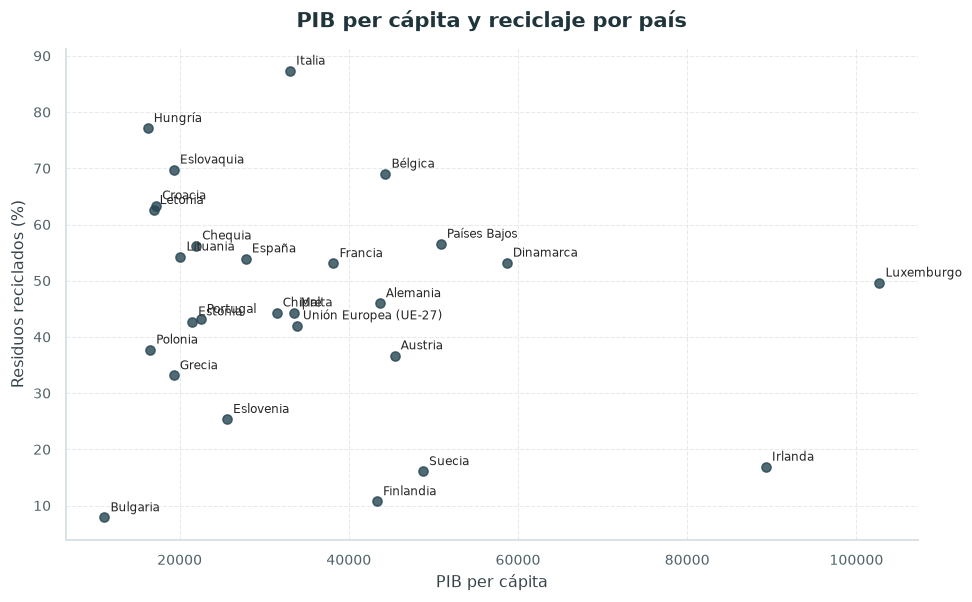

In [29]:
sns.regplot(
    data=reciclaje_gdp,
    x="gdp_pc",
    y="Valorización - reciclado",
    fit_reg= False
)

for _, row in reciclaje_gdp.iterrows():
    plt.annotate(
        row["pais"],
        (row["gdp_pc"], row["Valorización - reciclado"]),
        fontsize=8,
        xytext=(4, 4),
        textcoords="offset points"
    )

plt.xlabel("PIB per cápita")
plt.ylabel("Residuos reciclados (%)")
plt.title("PIB per cápita y reciclaje por país")

plt.show()

In [30]:
# Correlación de Pearson
pearson_corr, pearson_p = pearsonr(
    reciclaje_gdp["gdp_pc"],
    reciclaje_gdp["Valorización - reciclado"]
)

# Correlación de Spearman
spearman_corr, spearman_p = spearmanr(
    reciclaje_gdp["gdp_pc"],
    reciclaje_gdp["Valorización - reciclado"]
)

print("CORRELACIÓN DE PEARSON")
print(f"Coeficiente: {pearson_corr:.3f}")
print(f"P-valor: {pearson_p:.4f}")

print("\nCORRELACIÓN DE SPEARMAN")
print(f"Coeficiente: {spearman_corr:.3f}")
print(f"P-valor: {spearman_p:.4f}")

CORRELACIÓN DE PEARSON
Coeficiente: -0.179
P-valor: 0.3727

CORRELACIÓN DE SPEARMAN
Coeficiente: -0.146
P-valor: 0.4677


## 5. ¿Los países que más residuos generan son los que más reciclan?
Se compara generación per cápita y porcentaje de tratamiento mediante reciclaje para el mismo año. Se espera `Data/residuos_2024.csv` (columnas `pais`, `kg_per_capita`), generado por el notebook de limpieza de generación. Si no existe, se puede construir a partir del dataset de generación.

In [31]:
generacion_2024 = pd.read_csv("./Data/gen_2024.csv")

In [32]:
generacion_2024.head()

,pais,year,peligrosidad,actividad,residuo,kg_per_capita,toneladas,obs_flag,conf_status
0,Finlandia,2024,Total (peligrosos y no peligrosos),Todas las actividades NACE más los hogares,Total de residuos,21774.0,122367054.0,NaN,NaN
1,Suecia,2024,Total (peligrosos y no peligrosos),Todas las actividades NACE más los hogares,Total de residuos,17174.0,181521695.0,NaN,NaN
2,Bulgaria,2024,Total (peligrosos y no peligrosos),Todas las actividades NACE más los hogares,Total de residuos,14324.0,92268191.0,NaN,NaN
3,Luxemburgo,2024,Total (peligrosos y no peligrosos),Todas las actividades NACE más los hogares,Total de residuos,12165.0,8236110.0,NaN,NaN
4,Estonia,2024,Total (peligrosos y no peligrosos),Todas las actividades NACE más los hogares,Total de residuos,10239.0,14052064.0,NaN,NaN


In [33]:
# Comprobamos si hay algún "flag"
generacion_2024[['obs_flag', 'conf_status']].notna().sum().to_frame(name='valores_no_nan')

,valores_no_nan
obs_flag,2
conf_status,0


In [34]:
generacion_2024[~generacion_2024["obs_flag"].isna()]

,pais,year,peligrosidad,actividad,residuo,kg_per_capita,toneladas,obs_flag,conf_status
9,Unión Europea (UE-27),2024,Total (peligrosos y no peligrosos),Todas las actividades NACE más los hogares,Total de residuos,4872.0,2.195830e+09,i,NaN
19,Grecia,2024,Total (peligrosos y no peligrosos),Todas las actividades NACE más los hogares,Total de residuos,2894.0,3.002735e+07,p,NaN


In [35]:
# Los flags son porque el dato de UE es imputado por Eurostat y el de Grecia es provisional

In [36]:
# Nos quedamos solo con las columnas de pais y kg_per_capita para hacer el merge
gen_2024 = generacion_2024[["pais", "kg_per_capita"]].copy()

In [37]:
gen_reci = reci_prop.merge(
    gen_2024,
    on="pais",
    how="left"
)

gen_reci.head()

,pais,Valorización - reciclado,kg_per_capita
0,Italia,87.344827,3408.0
1,Hungría,77.136434,2692.0
2,Eslovaquia,69.761638,2336.0
3,Bélgica,69.027448,5909.0
4,Croacia,63.382579,2015.0


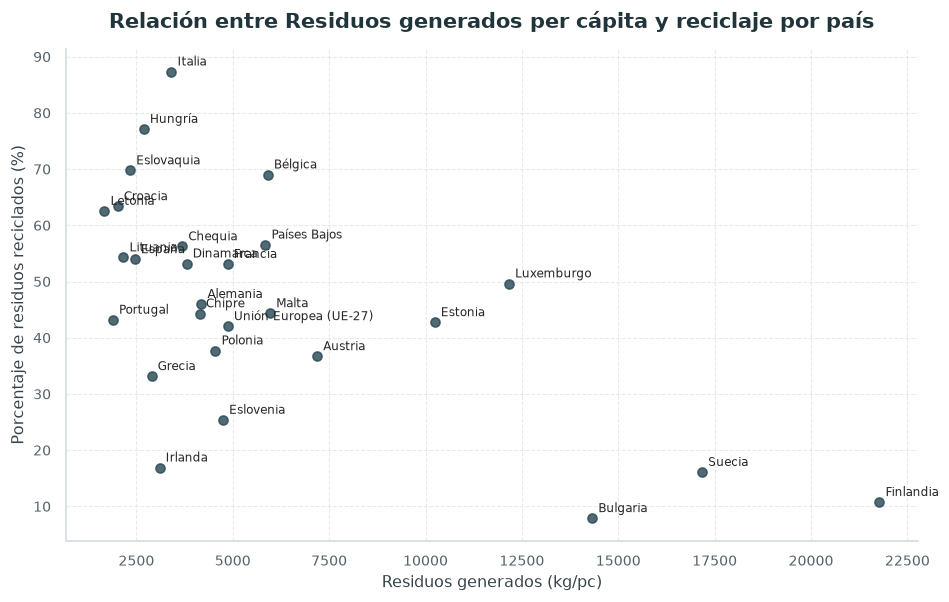

In [38]:
sns.regplot(
    data=gen_reci,
    x="kg_per_capita",
    y="Valorización - reciclado",
    fit_reg= False
)

for _, row in gen_reci.iterrows():
    plt.annotate(
        row["pais"],
        (row["kg_per_capita"], row["Valorización - reciclado"]),
        fontsize=8,
        xytext=(4, 4),
        textcoords="offset points"
    )

plt.xlabel("Residuos generados (kg/pc)")
plt.ylabel("Porcentaje de residuos reciclados (%)")
plt.title("Relación entre Residuos generados per cápita y reciclaje por país")

plt.show()

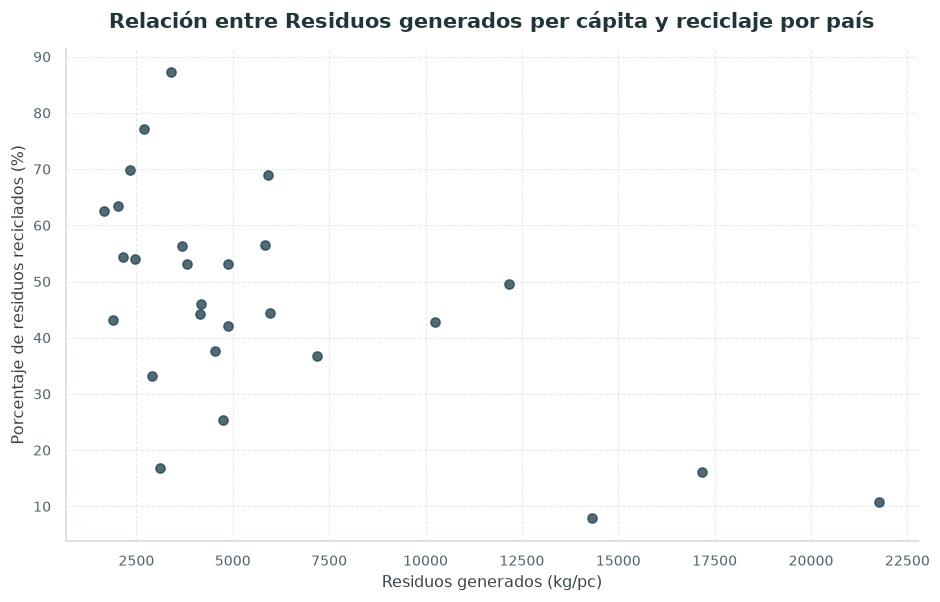

In [39]:
sns.regplot(
    data=gen_reci,
    x="kg_per_capita",
    y="Valorización - reciclado",
    fit_reg= False
)

plt.xlabel("Residuos generados (kg/pc)")
plt.ylabel("Porcentaje de residuos reciclados (%)")
plt.title("Relación entre Residuos generados per cápita y reciclaje por país")

plt.show()

In [40]:
# Correlación de Pearson
pearson_corr, pearson_p = pearsonr(
    gen_reci["kg_per_capita"],
    gen_reci["Valorización - reciclado"]
)

# Correlación de Spearman
spearman_corr, spearman_p = spearmanr(
    gen_reci["kg_per_capita"],
    gen_reci["Valorización - reciclado"]
)

print("CORRELACIÓN DE PEARSON")
print(f"Coeficiente: {pearson_corr:.3f}")
print(f"P-valor: {pearson_p:.4f}")

print("\nCORRELACIÓN DE SPEARMAN")
print(f"Coeficiente: {spearman_corr:.3f}")
print(f"P-valor: {spearman_p:.4f}")

CORRELACIÓN DE PEARSON
Coeficiente: -0.617
P-valor: 0.0006

CORRELACIÓN DE SPEARMAN
Coeficiente: -0.532
P-valor: 0.0043


## 6. ¿Qué tipos de residuos se reciclan más y cuáles se eliminan?
Se analiza la UE en el último año disponible, por tipo de residuo, excluyendo totales y subtotales para evitar doble conteo. Para cada categoría se calcula el reparto de operaciones respecto a `Tratamiento de residuos`.

In [41]:
cats_ue_2024 = df[
    (df["year"] == 2024) &
    (df["pais"] == UE) &
    (df["peligrosidad"] == "Total (peligrosos y no peligrosos)")
].copy()

cats_ue_2024 = cats_ue_2024[cats_ue_2024['tratamiento'].isin(treatments)]

cats_ue_2024.head()

,pais,year,peligrosidad,tratamiento,residuo,kg_per_capita,toneladas,obs_flag,conf_status
74332,Unión Europea (UE-27),2024,Total (peligrosos y no peligrosos),Eliminación - incineración (D10),"Residuos ácidos, alcalinos o salinos",0.0,60000.0,i,NaN
74555,Unión Europea (UE-27),2024,Total (peligrosos y no peligrosos),Eliminación - incineración (D10),Residuos animales y mezclados de alimentos,0.0,200000.0,i,NaN
74778,Unión Europea (UE-27),2024,Total (peligrosos y no peligrosos),Eliminación - incineración (D10),"Heces de animales, orina y estiércol",1.0,390000.0,i,NaN
75001,Unión Europea (UE-27),2024,Total (peligrosos y no peligrosos),Eliminación - incineración (D10),Residuos de pilas y acumuladores,0.0,10000.0,i,NaN
75308,Unión Europea (UE-27),2024,Total (peligrosos y no peligrosos),Eliminación - incineración (D10),Residuos químicos,3.0,1530000.0,i,NaN


In [42]:
group_mapping = {
    # --- BLOQUE MINERAL Y CONSTRUCCIÓN ---
    'Residuos minerales de construcción y demolición': 'Mineral y Construcción',
    'Otros residuos minerales (W122+W123+W125)': 'Mineral y Construcción',
    'Tierras y suelos': 'Mineral y Construcción',
    'Lodos de dragado': 'Mineral y Construcción',
    'Residuos minerales del tratamiento de residuos y residuos estabilizados': 'Mineral y Construcción',
    'Residuos de combustión': 'Mineral y Construcción',

    # --- BLOQUE RECICLABLES CLÁSICOS ---
    'Residuos de papel y cartón': 'Reciclables Clásicos',
    'Residuos de vidrio': 'Reciclables Clásicos',
    'Residuos de plástico': 'Reciclables Clásicos',
    'Residuos de madera': 'Reciclables Clásicos',
    'Residuos textiles': 'Reciclables Clásicos',
    'Residuos de caucho': 'Reciclables Clásicos',
    'Residuos metálicos mezclados férreos y no férreos': 'Reciclables Clásicos',
    'Equipos desechados (excepto vehículos desechados y residuos de pilas y acumuladores) (W08 excepto W081, W0841)': 'Reciclables Clásicos',
    'Residuos de pilas y acumuladores': 'Reciclables Clásicos',

    # --- BLOQUE URBANO Y MIXTO ---
    'Residuos domésticos y similares': 'Urbano y Mixto',
    'Materiales mezclados e indiferenciados': 'Urbano y Mixto',
    'Lodos comunes': 'Urbano y Mixto',

    # --- BLOQUE ORGÁNICO Y BIOMASA ---
    'Residuos vegetales': 'Orgánico y Biomasa',
    'Residuos animales y mezclados de alimentos': 'Orgánico y Biomasa',
    'Heces de animales, orina y estiércol': 'Orgánico y Biomasa',

    # --- BLOQUE QUÍMICO E INDUSTRIAL ---
    'Residuos ácidos, alcalinos o salinos': 'Químico e Industrial',
    'Residuos químicos': 'Químico e Industrial',
    'Aceites usados': 'Químico e Industrial',
    'Lodos de efluentes industriales': 'Químico e Industrial',
    'Lodos y residuos líquidos del tratamiento de residuos': 'Químico e Industrial',
    'Residuos sanitarios y biológicos': 'Químico e Industrial'
}

# Creamos la nueva columna 'Group' usando el mapeo
cats_ue_2024['Group'] = cats_ue_2024['residuo'].map(group_mapping)

# Filtramos el DataFrame: nos quedamos solo con las que tienen grupo (elimina duplicados/basura)
df_grouped = cats_ue_2024.dropna(subset=['Group']).copy()

In [43]:
df_grouped

,pais,year,peligrosidad,tratamiento,residuo,kg_per_capita,toneladas,obs_flag,conf_status,Group
74332,Unión Europea (UE-27),2024,Total (peligrosos y no peligrosos),Eliminación - incineración (D10),"Residuos ácidos, alcalinos o salinos",0.0,60000.0,i,NaN,Químico e Industrial
74555,Unión Europea (UE-27),2024,Total (peligrosos y no peligrosos),Eliminación - incineración (D10),Residuos animales y mezclados de alimentos,0.0,200000.0,i,NaN,Orgánico y Biomasa
74778,Unión Europea (UE-27),2024,Total (peligrosos y no peligrosos),Eliminación - incineración (D10),"Heces de animales, orina y estiércol",1.0,390000.0,i,NaN,Orgánico y Biomasa
75001,Unión Europea (UE-27),2024,Total (peligrosos y no peligrosos),Eliminación - incineración (D10),Residuos de pilas y acumuladores,0.0,10000.0,i,NaN,Reciclables Clásicos
75308,Unión Europea (UE-27),2024,Total (peligrosos y no peligrosos),Eliminación - incineración (D10),Residuos químicos,3.0,1530000.0,i,NaN,Químico e Industrial
...,...,...,...,...,...,...,...,...,...,...
148716,Unión Europea (UE-27),2024,Total (peligrosos y no peligrosos),Tratamiento de residuos,Tierras y suelos,992.0,446600000.0,i,NaN,Mineral y Construcción
149496,Unión Europea (UE-27),2024,Total (peligrosos y no peligrosos),Tratamiento de residuos,Residuos textiles,3.0,1420000.0,i,NaN,Reciclables Clásicos
150110,Unión Europea (UE-27),2024,Total (peligrosos y no peligrosos),Tratamiento de residuos,Aceites usados,5.0,2300000.0,i,NaN,Químico e Industrial
150390,Unión Europea (UE-27),2024,Total (peligrosos y no peligrosos),Tratamiento de residuos,Residuos vegetales,96.0,43240000.0,i,NaN,Orgánico y Biomasa


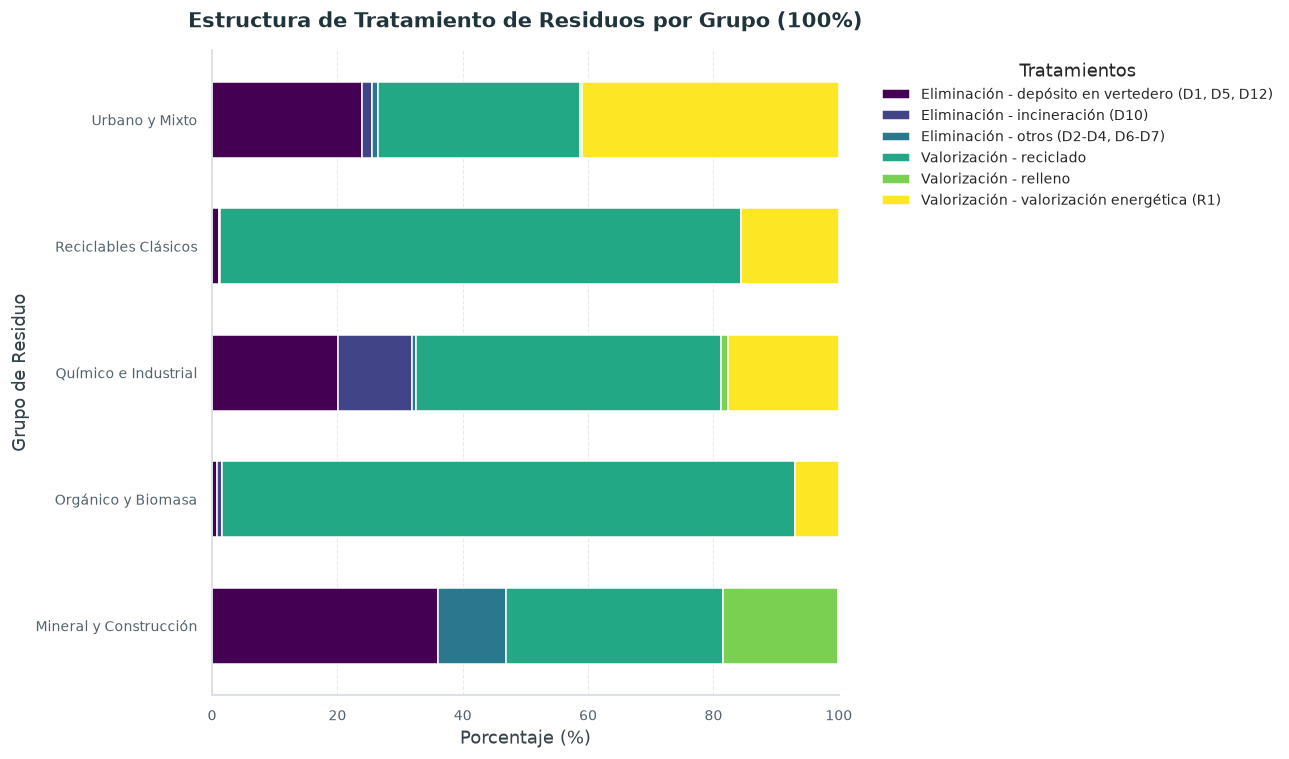

In [44]:
df_pivot_group = df_grouped.pivot_table(
    index='Group',
    columns='tratamiento',
    values='toneladas',
    aggfunc='sum'
).fillna(0)  # Rellenar con 0 si algún grupo no tiene datos en un tratamiento

# 3. Convertir a porcentajes dividiendo cada fila entre la suma total de esa fila
df_pivot_group = df_pivot_group.drop(columns = ["Tratamiento de residuos"])
totales_por_grupo = df_pivot_group.sum(axis=1)
df_perc_group = df_pivot_group.div(totales_por_grupo, axis=0) * 100

# 4. Dibujar el gráfico por grupos
plt.figure(figsize=(12, 7))
df_perc_group.plot(kind='barh', stacked=True, cmap='viridis', width=0.6, ax=plt.gca())

plt.title('Estructura de Tratamiento de Residuos por Grupo (100%)', fontsize=14, pad=15)
plt.xlabel('Porcentaje (%)', fontsize=12)
plt.ylabel('Grupo de Residuo', fontsize=12)
plt.legend(title='Tratamientos', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xlim(0, 100)
plt.tight_layout()
plt.show()

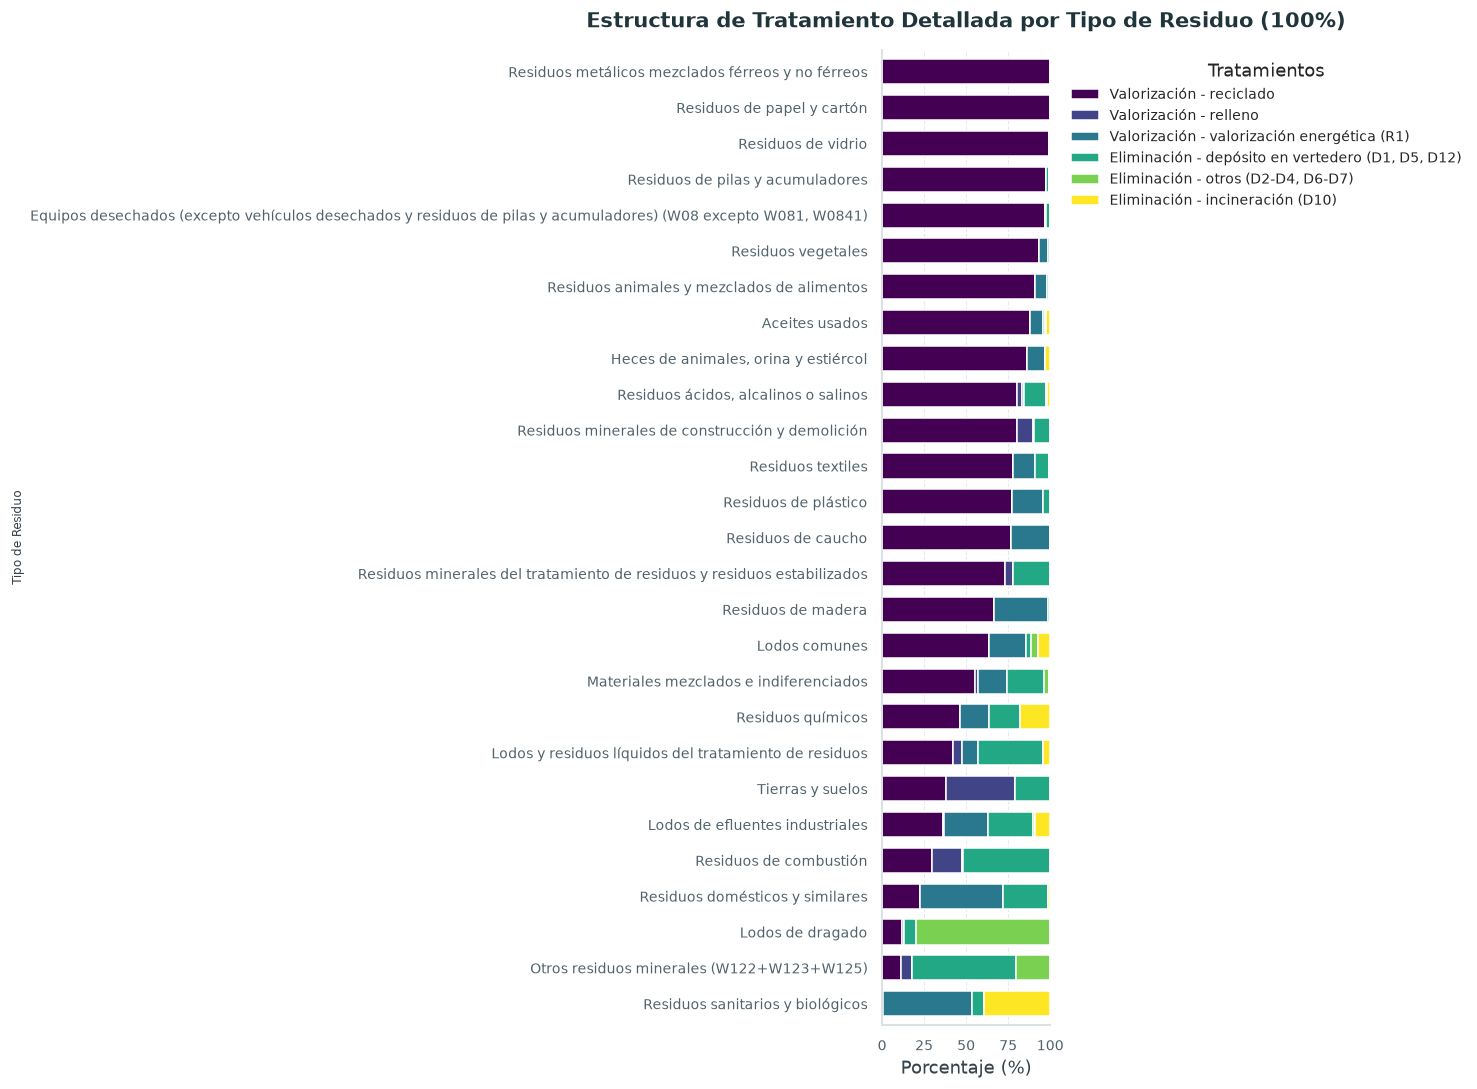

In [45]:
df_pivot_cats = df_grouped.pivot_table(
    index='residuo', 
    columns='tratamiento', 
    values='toneladas', 
    aggfunc='sum'
)

# Reordenamos el DataFrame
df_pivot_cats = df_pivot_cats[nuevo_orden]

# Si existe esa columna la usamos; si no, sumamos las columnas individuales
col_total = 'Tratamiento de residuos'

if col_total in df_pivot_cats.columns:
    # Seleccionamos todas las columnas EXCEPTO la del total
    treatments_es = [col for col in df_pivot_cats.columns if col != col_total]
    df_perc_cats = df_pivot_cats[treatments_es].div(df_pivot_cats[col_total], axis=0) * 100
else:
    # Si no existe columna de total, calculamos el 100% sumando cada fila
    df_perc_cats = df_pivot_cats.div(df_pivot_cats.sum(axis=1), axis=0) * 100

# 4. Ordenar por la columna de reciclado en español
col_reciclado = 'Valorización - reciclado'
if col_reciclado in df_perc_cats.columns:
    df_perc_cats = df_perc_cats.sort_values(by=col_reciclado, ascending=True)

# 5. Dibujar el gráfico detallado
plt.figure(figsize=(14, 10))
df_perc_cats.plot(kind='barh', stacked=True, cmap='viridis', width=0.7, ax=plt.gca())

plt.title('Estructura de Tratamiento Detallada por Tipo de Residuo (100%)', fontsize=14, pad=15)
plt.xlabel('Porcentaje (%)', fontsize=12)
plt.ylabel('Tipo de Residuo', fontsize=8)
plt.legend(title='Tratamientos', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xlim(0, 100)
plt.tight_layout()
plt.show()

## 8. Conclusiones
- Observamos que la tasa de reciclaje tiene una tendencia ascendente en los últimos años en la UE.
- Italia es el país que más recicla proporcionalmente, mientras que Finlandia y Suecia están por la cola.
- Al analizar si los países nórdicos reciclan más, el análisis estadístico como Mann–Whitney muestran que no se puede decir confirmar la hipótesis.
- Tampoco se puede confirmar que los países que más residuos generan son los que más reciclan, ni que los que mayor PIB per capita tienen reciclen más.
- Por último, se ven diferencias en el tratamiento según el tipo de residuo.